In [8]:
import pandas as pd
import numpy as np

In [14]:
# 1. Cargar el dataset (asumiendo que cargamos el archivo csv)
df = pd.read_csv("C:\\Users\\marti\\Desktop\\EDA\\archive\\stell-faults.csv", sep=",")

In [19]:
df.head()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [20]:
# 1. Identificar las últimas 7 columnas del dataset por posición
columnas_defectos_viejas = df.columns[-7:]

# 2. Crear una lista con los nombres limpios que queremos ponerles
nombres_defectos = ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# 3. Renombrar temporalmente esas últimas 7 columnas para que Python no se confunda
df.rename(columns=dict(zip(columnas_defectos_viejas, nombres_defectos)), inplace=True)

# 4. Ahora sí, aplicar el idxmax sin fallos
df['Tipo_Defecto'] = df[nombres_defectos].idxmax(axis=1)

# 5. Opcional: Eliminar las 7 columnas originales si ya no las necesitas en binario
df.drop(columns=nombres_defectos, inplace=True)

In [21]:
df

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Tipo_Defecto
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1936,249,277,325780,325796,273,54,22,35033,119,141,...,0.5185,0.7273,0.0,2.4362,1.4472,1.2041,-0.4286,0.0026,0.7254,Other_Faults
1937,144,175,340581,340598,287,44,24,34599,112,133,...,0.7046,0.7083,0.0,2.4579,1.4914,1.2305,-0.4516,-0.0582,0.8173,Other_Faults
1938,145,174,386779,386794,292,40,22,37572,120,140,...,0.7250,0.6818,0.0,2.4654,1.4624,1.1761,-0.4828,0.0052,0.7079,Other_Faults
1939,137,170,422497,422528,419,97,47,52715,117,140,...,0.3402,0.6596,0.0,2.6222,1.5185,1.4914,-0.0606,-0.0171,0.9919,Other_Faults


In [26]:
# 1. Seguridad: Eliminamos espacios en blanco ocultos en los nombres de las columnas
df.columns = df.columns.str.strip()

# 2. Selección de las variables clave para el negocio
variables_clave = [
    'Pixels_Areas',           # Tamaño físico del defecto
    'Steel_Plate_Thickness',  # Grosor de la lámina de acero
    'Sum_of_Luminosity',      # Brillo / Intensidad lumínica
    'Length_of_Conveyer'      # Longitud de la cinta transportadora
]

# 3. Creamos la tabla resumen calculando la media (promedio) por cada fallo
tabla_resumen = df.groupby('Tipo_Defecto')[variables_clave].mean().round(2)

# 4. Añadimos el conteo de cuántos casos hay de cada uno
tabla_resumen['Cantidad_Casos'] = df['Tipo_Defecto'].value_counts()

# 5. Reorganizamos y ordenamos por tamaño del defecto
columnas_ordenadas = ['Cantidad_Casos'] + variables_clave
tabla_resumen = tabla_resumen[columnas_ordenadas].sort_values(by='Pixels_Areas', ascending=False)

# 6. MOSTRAR COMO DATAFRAME VISUAL (Sin print)
tabla_resumen

,Cantidad_Casos,Pixels_Areas,Steel_Plate_Thickness,Sum_of_Luminosity,Length_of_Conveyer
Tipo_Defecto,,,,,
K_Scratch,391,7622.65,40.18,835433.60,1384.03
Other_Faults,673,584.37,102.60,61570.49,1485.37
Pastry,158,561.62,92.91,61262.84,1554.43
Z_Scratch,190,506.59,74.58,51466.19,1357.86
Dirtiness,55,363.49,84.45,40545.05,1414.64
Bumps,402,238.47,76.93,26102.78,1522.94
Stains,72,19.92,50.69,2486.12,1358.39


--- Grosor Promedio (en mm) por cada Tipo de Defecto ---
Tipo_Defecto  Steel_Plate_Thickness
Other_Faults             102.600297
      Pastry              92.905063
   Dirtiness              84.454545
       Bumps              76.930348
   Z_Scratch              74.578947
      Stains              50.694444
   K_Scratch              40.179028


C:\Users\marti\AppData\Local\Temp\ipykernel_8240\1153097946.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


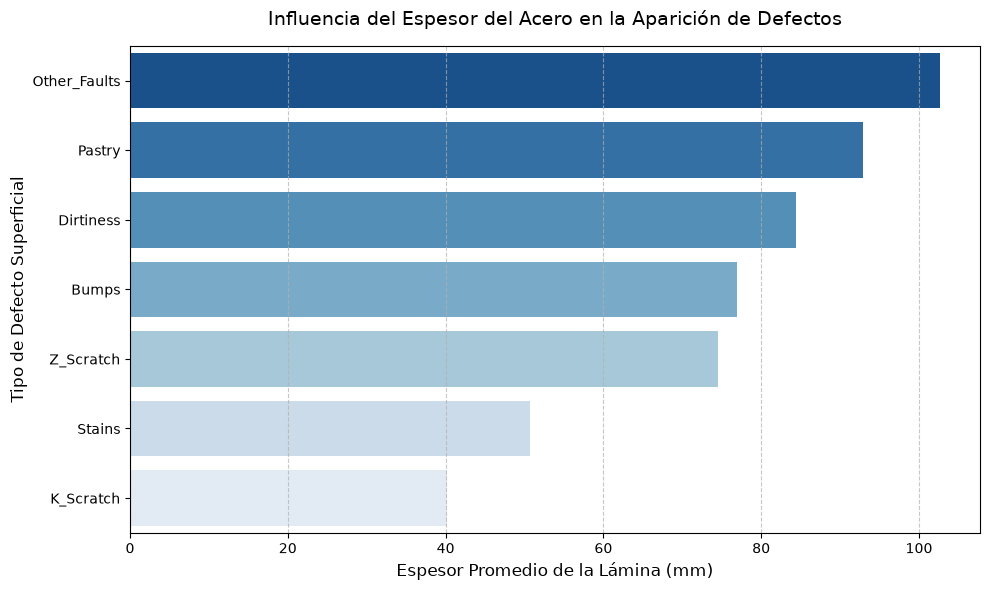

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Limpieza de nombres por seguridad
df.columns = df.columns.str.strip()

# 2. Análisis Estadístico: Agrupar por defecto y calcular la media del espesor
espesor_por_defecto = (
    df.groupby("Tipo_Defecto")["Steel_Plate_Thickness"]
    .mean()
    .reset_index()
)
espesor_por_defecto = espesor_por_defecto.sort_values(
    by="Steel_Plate_Thickness", ascending=False
)

print("--- Grosor Promedio (en mm) por cada Tipo de Defecto ---")
print(espesor_por_defecto.to_string(index=False))

# 3. Gráfico de Barras de Medias (Sustituto recomendado del Boxplot)
plt.figure(figsize=(10, 6))

# Usamos un gráfico de barras horizontal para que los nombres de los defectos se lean a la perfección
sns.barplot(
    x="Steel_Plate_Thickness",
    y="Tipo_Defecto",
    data=espesor_por_defecto,
    palette="Blues_r",  # Degradado de azul (más oscuro = más grueso)
)

# Estilizado estético para la presentación del Bootcamp
plt.title(
    "Influencia del Espesor del Acero en la Aparición de Defectos",
    fontsize=14,
    pad=15,
)
plt.xlabel("Espesor Promedio de la Lámina (mm)", fontsize=12)
plt.ylabel("Tipo de Defecto Superficial", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)  # Líneas de guía sutiles

# Mostrar el gráfico como objeto visual en el notebook
plt.tight_layout()
plt.show()